# Autoregressive Text Generation with Simple RNN, Bidirectional RNN, LSTM and GRU

**Course:** Foundations of Generative AI (ICT4403), Assignment 2
**Dataset:** *The Adventures of Sherlock Holmes* by Arthur Conan Doyle, Project Gutenberg eBook #1661: <https://www.gutenberg.org/ebooks/1661> (plain text: <https://www.gutenberg.org/cache/epub/1661/pg1661.txt>)

**Objective.** Build a word-level autoregressive language model that reads the previous 15 tokens and predicts the next one. New text is generated by sampling a word, appending it to the context and repeating. Four recurrent architectures (Simple RNN, Bidirectional RNN, LSTM, GRU) are trained under identical conditions and compared on:

* quantitative measures: cross-entropy loss, perplexity, top-1 / top-5 next-word accuracy and training time
* the generated text: coherence, diversity, contextual consistency and repetition
* the effect of the sampling temperature (0.2, 0.5, 1.0, 1.5) on all of the above

**Notebook outline**

1. Setup and the shared experimental configuration
2. Dataset loading and characteristics (Task i)
3. Preprocessing and input–target sequence construction (Task i)
4. Model definitions and training (Task i)
5. Quantitative evaluation (Task ii)
6. Text generation and qualitative evaluation (Task ii)
7. Sampling-temperature analysis (Task iii)
8. Conclusion: the best model (Task iii)

## 1. Setup and experimental configuration

Every model uses the same data split, vocabulary, context length, embedding size, hidden size, depth, dropout, optimiser, learning-rate schedule, batch size, early-stopping rule and random seed. The only thing that changes between runs is the recurrent cell.

In [1]:
import os, re, json, time, math, random, copy, urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

DATA_URL = 'https://www.gutenberg.org/cache/epub/1661/pg1661.txt'
DATA_PATH = 'data/pg1661.txt'
RESULTS_DIR, PLOTS_DIR, MODELS_DIR = 'results', 'results/plots', 'models'
for d in ('data', RESULTS_DIR, PLOTS_DIR, MODELS_DIR):
    os.makedirs(d, exist_ok=True)

# Shared hyper-parameters (identical for all four models)
CFG = dict(
    seq_len=15,        # context window: 15 previous tokens -> next token
    min_freq=2,        # words seen fewer than 2 times in the training split become <unk>
    embed_dim=128,
    hidden_dim=256,    # per direction
    num_layers=2,
    dropout=0.3,
    batch_size=128,
    lr=1e-3,           # Adam
    lr_factor=0.5,     # ReduceLROnPlateau on validation loss
    lr_patience=1,
    max_epochs=30,
    patience=4,        # early stopping on validation loss (best weights restored)
    clip=1.0,          # gradient-norm clipping
)
MODEL_NAMES = ['SimpleRNN', 'BiRNN', 'LSTM', 'GRU']
TEMPERATURES = [0.2, 0.5, 1.0, 1.5]
N_GEN_WORDS = 50          # tokens generated per sample
N_SAMPLES_PER_SEED = 10   # independent samples per (model, temperature, seed)

print(f'PyTorch {torch.__version__} | NumPy {np.__version__} | pandas {pd.__version__} | matplotlib {matplotlib.__version__}')
print('Device:', DEVICE, f'({torch.cuda.get_device_name(0)})' if DEVICE.type == 'cuda' else '')
pd.DataFrame({'hyper-parameter': list(CFG), 'value': [str(v) for v in CFG.values()]})

PyTorch 2.11.0+cu128 | NumPy 2.5.4 | pandas 3.0.6 | matplotlib 3.11.2
Device: cuda (NVIDIA GeForce RTX 4060 Laptop GPU)


,hyper-parameter,value
0,seq_len,15
1,min_freq,2
2,embed_dim,128
3,hidden_dim,256
4,num_layers,2
5,dropout,0.3
6,batch_size,128
7,lr,0.001
8,lr_factor,0.5
9,lr_patience,1


## 2. Dataset: *The Adventures of Sherlock Holmes* (Task i)

**Source.** Project Gutenberg eBook #1661 (public domain): <https://www.gutenberg.org/ebooks/1661>. The notebook downloads the plain-text UTF-8 file if `data/pg1661.txt` is not already present.

**Why this dataset.** It is a single-author collection of twelve short stories (1891–1892) with a consistent narrative voice (Dr Watson's first-person narration plus a lot of dialogue), recurring entities (Holmes, Watson, Baker Street) and formal Victorian prose. A consistent style suits next-word modelling, and at about 120k tokens the corpus is small enough to train four models under identical conditions, yet large enough to show clear differences between them.

**Cleaning of the raw file.** The Project Gutenberg licence header and footer, the title page and the table of contents are removed. So are the story headings and section numerals (`I.`, `II.`, …), which are not part of the prose.

In [2]:
if not os.path.exists(DATA_PATH):
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)
with open(DATA_PATH, encoding='utf-8') as f:
    raw = f.read()

start = raw.index('*** START OF THE PROJECT GUTENBERG EBOOK')
end = raw.index('*** END OF THE PROJECT GUTENBERG EBOOK')
body = raw[raw.index('\n', start) + 1:end]
body = body[body.index('I. A SCANDAL IN BOHEMIA'):]          # skip title page and table of contents

HEADING_RE = re.compile(r"^\s*[IVXL]+\.(\s+[A-Z0-9’'\-\s,\.]+)?\s*$")   # e.g. "II. THE RED-HEADED LEAGUE", "III."
removed = [l.strip() for l in body.splitlines() if HEADING_RE.match(l)]
body = '\n'.join(l for l in body.splitlines() if not HEADING_RE.match(l)).strip()

print(f'Raw file: {len(raw):,} characters; story text kept: {len(body):,} characters')
print(f'Removed {len(removed)} heading lines, e.g.:', removed[:5])
print('\n--- first 600 characters of the story text ---\n')
print(body[:600])

Raw file: 581,601 characters; story text kept: 561,229 characters
Removed 16 heading lines, e.g.: ['I. A SCANDAL IN BOHEMIA', 'I.', 'II.', 'III.', 'II. THE RED-HEADED LEAGUE']

--- first 600 characters of the story text ---

To Sherlock Holmes she is always _the_ woman. I have seldom heard him
mention her under any other name. In his eyes she eclipses and
predominates the whole of her sex. It was not that he felt any emotion
akin to love for Irene Adler. All emotions, and that one particularly,
were abhorrent to his cold, precise but admirably balanced mind. He
was, I take it, the most perfect reasoning and observing machine that
the world has seen, but as a lover he would have placed himself in a
false position. He never spoke of the softer passions, save with a gibe
and a sneer. They were admirable things for th


In [3]:
paragraphs = [p for p in re.split(r'\n\s*\n', body) if p.strip()]
raw_words = re.findall(r"[A-Za-z]+(?:['’][A-Za-z]+)*", body)
flat = re.sub(r'\s+', ' ', body)
flat = re.sub(r'\b(Mr|Mrs|Dr|St|Messrs)\.', r'\1', flat)   # abbreviations are not sentence ends
sentences = [s for s in re.split(r'(?<=[.!?])["”’]?\s+', flat) if re.search(r'[A-Za-z]', s)]
sent_lens = [len(re.findall(r"[A-Za-z]+(?:['’][A-Za-z]+)*", s)) for s in sentences]
dialogue_paragraphs = sum('“' in p for p in paragraphs)

dataset_stats = {
    'Stories': 12,
    'Characters (story text)': len(body),
    'Paragraphs': len(paragraphs),
    'Paragraphs containing dialogue (%)': round(100 * dialogue_paragraphs / len(paragraphs), 1),
    'Sentences (approx.)': len(sentences),
    'Words (raw)': len(raw_words),
    'Distinct words (case-insensitive)': len({w.lower().replace('’', "'") for w in raw_words}),
    'Mean words per sentence': round(float(np.mean(sent_lens)), 2),
    'Median words per sentence': float(np.median(sent_lens)),
}
pd.DataFrame({'characteristic': list(dataset_stats), 'value': [f'{v:,}' for v in dataset_stats.values()]})

,characteristic,value
0,Stories,12
1,Characters (story text),"561,229"
2,Paragraphs,"2,527"
3,Paragraphs containing dialogue (%),90.7
4,Sentences (approx.),"6,805"
5,Words (raw),"105,139"
6,Distinct words (case-insensitive),"7,930"
7,Mean words per sentence,15.45
8,Median words per sentence,12.0


## 3. Preprocessing and input–target sequence construction (Task i)

**Text normalisation and tokenisation**

1. Lower-case everything, normalise curly quotes/apostrophes to ASCII and turn em-dashes, hyphens and italics underscores into spaces.
2. Remove the full stop after the abbreviations *Mr., Mrs., Dr., St., Messrs.* so it is not mistaken for a sentence boundary.
3. Tokenise into words (contractions and possessives kept whole, e.g. `holmes's`, `don't`), numbers, and the punctuation marks `. , ! ? ; :`. Punctuation stays in the vocabulary so the models learn sentence and clause boundaries and the generated text is readable. Quotation marks and brackets are dropped.

**Split.** The token stream is split *contiguously* into 80 % train, 10 % validation and 10 % test. Overlapping sliding windows therefore never leak text from the training set into the evaluation sets. The validation and test sets are mostly the last two stories (*The Beryl Coronet*, *The Copper Beeches*), so evaluation measures generalisation to unseen narrative.

**Vocabulary.** Built from the training split only. Tokens that occur at least twice are kept; everything else maps to `<unk>`. Index 0 is `<pad>` and index 1 is `<unk>`.

**Autoregressive input–target pairs.** A window of `seq_len = 15` tokens slides over each split with stride 1. The 15 tokens are the input and the token that follows is the target (many-to-one):

$$x^{(t)} = (w_{t-15}, \dots, w_{t-1}) \;\longrightarrow\; y^{(t)} = w_t$$

so the model learns $P(w_t \mid w_{t-15}, \dots, w_{t-1})$. Windows whose target is `<unk>` are removed, so the models never learn to emit `<unk>` and the accuracy is not inflated by predicting it. `<unk>` can still appear inside a context.

In [4]:
ABBREVIATIONS = ['mr', 'mrs', 'dr', 'st', 'messrs']
TOKEN_RE = re.compile(r"[a-z]+(?:'[a-z]+)*|[0-9]+|[.,!?;:]")
PUNCT = set('.,!?;:')

def clean_text(text):
    text = text.lower()
    text = text.replace('’', "'").replace('‘', "'").replace('“', '"').replace('”', '"')
    text = text.replace('—', ' ').replace('–', ' ').replace('-', ' ').replace('_', ' ')
    text = re.sub(r"\b(" + '|'.join(ABBREVIATIONS) + r")\.", r"\1", text)
    return text

def tokenize(text):
    return TOKEN_RE.findall(clean_text(text))

tokens = tokenize(body)
example = body[:183]
print('Original :', example.replace('\n', ' '))
print('Tokens   :', tokenize(example))
print(f'\nTotal tokens: {len(tokens):,} | distinct tokens: {len(set(tokens)):,}')

Original : To Sherlock Holmes she is always _the_ woman. I have seldom heard him mention her under any other name. In his eyes she eclipses and predominates the whole of her sex. It was not that
Tokens   : ['to', 'sherlock', 'holmes', 'she', 'is', 'always', 'the', 'woman', '.', 'i', 'have', 'seldom', 'heard', 'him', 'mention', 'her', 'under', 'any', 'other', 'name', '.', 'in', 'his', 'eyes', 'she', 'eclipses', 'and', 'predominates', 'the', 'whole', 'of', 'her', 'sex', '.', 'it', 'was', 'not', 'that']

Total tokens: 120,028 | distinct tokens: 8,001


                 token statistic       value
    Tokens (words + punctuation) 120028.0000
                     Word tokens 105277.0000
              Punctuation tokens  14751.0000
             Distinct word types   7995.0000
        Type-token ratio (words)      0.0759
Hapax legomena (words seen once)   3553.0000
   Hapax share of word types (%)     44.4000

20 most frequent tokens: [(',', 7659), ('.', 5750), ('the', 5595), ('and', 3018), ('i', 2999), ('to', 2744), ('of', 2640), ('a', 2639), ('in', 1764), ('that', 1744), ('it', 1701), ('you', 1481), ('he', 1467), ('was', 1410), ('his', 1159), ('is', 1124), ('my', 1007), ('have', 924), ('as', 852), ('had', 831)]


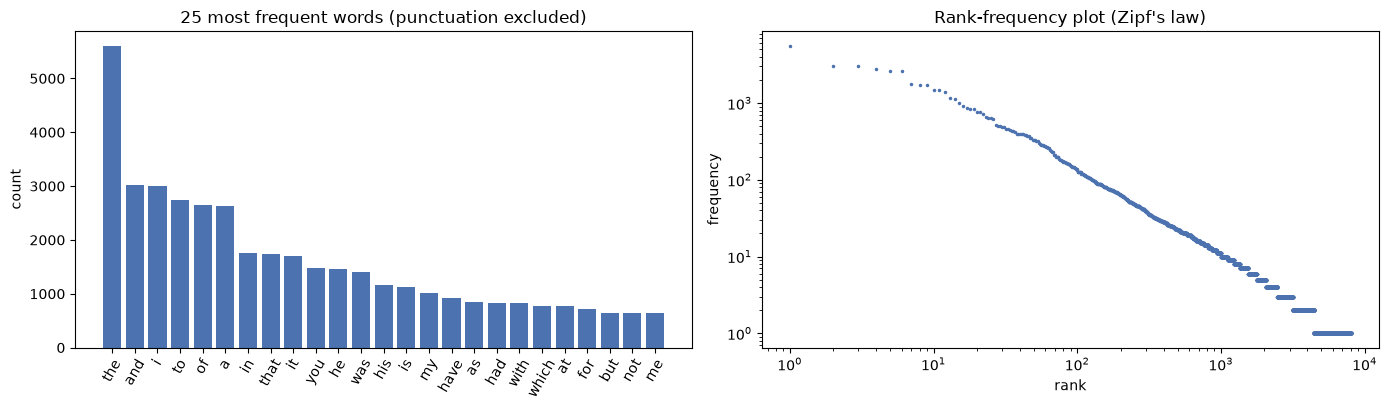

In [5]:
tok_counts = Counter(tokens)
word_counts = Counter(t for t in tokens if t not in PUNCT)
hapax = sum(1 for c in word_counts.values() if c == 1)
token_stats = {
    'Tokens (words + punctuation)': len(tokens),
    'Word tokens': sum(word_counts.values()),
    'Punctuation tokens': len(tokens) - sum(word_counts.values()),
    'Distinct word types': len(word_counts),
    'Type-token ratio (words)': round(len(word_counts) / sum(word_counts.values()), 4),
    'Hapax legomena (words seen once)': hapax,
    'Hapax share of word types (%)': round(100 * hapax / len(word_counts), 1),
}
dataset_stats.update(token_stats)
print(pd.DataFrame(token_stats.items(), columns=['token statistic', 'value']).to_string(index=False))
print('\n20 most frequent tokens:', tok_counts.most_common(20))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
top = word_counts.most_common(25)
axes[0].bar([w for w, _ in top], [c for _, c in top], color='#4C72B0')
axes[0].set_title('25 most frequent words (punctuation excluded)')
axes[0].tick_params(axis='x', rotation=60)
axes[0].set_ylabel('count')
freqs = np.array(sorted(word_counts.values(), reverse=True))
axes[1].loglog(np.arange(1, len(freqs) + 1), freqs, '.', ms=3, color='#4C72B0')
axes[1].set_title("Rank-frequency plot (Zipf's law)")
axes[1].set_xlabel('rank'); axes[1].set_ylabel('frequency')
plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/01_dataset_characteristics.png', dpi=150)
plt.show()

In [6]:
n = len(tokens)
n_train, n_val = int(0.8 * n), int(0.1 * n)
train_tok = tokens[:n_train]
val_tok = tokens[n_train:n_train + n_val]
test_tok = tokens[n_train + n_val:]

train_counts = Counter(train_tok)
itos = ['<pad>', '<unk>'] + [w for w, c in sorted(train_counts.items(), key=lambda kv: (-kv[1], kv[0])) if c >= CFG['min_freq']]
stoi = {w: i for i, w in enumerate(itos)}
PAD, UNK = stoi['<pad>'], stoi['<unk>']
V = len(itos)

def encode(toks):
    return [stoi.get(t, UNK) for t in toks]

train_ids, val_ids, test_ids = encode(train_tok), encode(val_tok), encode(test_tok)

split_rows = []
for name, ids in [('train', train_ids), ('validation', val_ids), ('test', test_ids)]:
    split_rows.append({'split': name, 'tokens': len(ids), '<unk> rate (%)': round(100 * ids.count(UNK) / len(ids), 2)})
print(f'Vocabulary size (incl. <pad>, <unk>): {V:,}')
dataset_stats['Vocabulary size'] = V
pd.DataFrame(split_rows)

Vocabulary size (incl. <pad>, <unk>): 3,918


,split,tokens,<unk> rate (%)
0,train,96022,3.51
1,validation,12002,6.07
2,test,12004,7.29


In [7]:
def make_sequences(ids, seq_len=CFG['seq_len']):
    """Sliding windows: X[i] = ids[i : i+seq_len], y[i] = ids[i+seq_len]; windows with an <unk> target are dropped."""
    ids = torch.tensor(ids, dtype=torch.long)
    X = ids.unfold(0, seq_len, 1)[:-1]
    y = ids[seq_len:]
    keep = y != UNK
    return X[keep].contiguous(), y[keep].contiguous()

X_train, y_train = make_sequences(train_ids)
X_val, y_val = make_sequences(val_ids)
X_test, y_test = make_sequences(test_ids)
print(f'X_train {tuple(X_train.shape)}  y_train {tuple(y_train.shape)}')
print(f'X_val   {tuple(X_val.shape)}  y_val   {tuple(y_val.shape)}')
print(f'X_test  {tuple(X_test.shape)}  y_test  {tuple(y_test.shape)}\n')

print('Example input -> target pairs (decoded):')
for i in range(0, 5):
    print(f"  {' '.join(itos[j] for j in X_train[i].tolist()):<90} -> {itos[y_train[i].item()]}")

dataset_stats.update({'Training sequences': len(y_train), 'Validation sequences': len(y_val), 'Test sequences': len(y_test)})
with open(f'{RESULTS_DIR}/dataset_statistics.json', 'w') as f:
    json.dump(dataset_stats, f, indent=2)

# keep all sequences on the device; the dataset is small
X_train, y_train, X_val, y_val, X_test, y_test = (t.to(DEVICE) for t in (X_train, y_train, X_val, y_val, X_test, y_test))

X_train (92634, 15)  y_train (92634,)
X_val   (11259, 15)  y_val   (11259,)
X_test  (11116, 15)  y_test  (11116,)

Example input -> target pairs (decoded):
  to sherlock holmes she is always the woman . i have seldom heard him mention               -> her
  sherlock holmes she is always the woman . i have seldom heard him mention her              -> under
  holmes she is always the woman . i have seldom heard him mention her under                 -> any
  she is always the woman . i have seldom heard him mention her under any                    -> other
  is always the woman . i have seldom heard him mention her under any other                  -> name


## 4. Models and training (Task i)

All four models share one architecture template and differ only in the recurrent encoder:

`Embedding(V, 128) → Dropout → 2-layer recurrent encoder (256 units) → final hidden state → Dropout → Linear(·, V) → softmax`

| Model | Recurrent encoder | What it adds |
|---|---|---|
| **Simple RNN** | `nn.RNN` (tanh), unidirectional | Baseline Elman recurrence $h_t = \tanh(W_x x_t + W_h h_{t-1} + b)$. Prone to vanishing gradients over long contexts. |
| **Bidirectional RNN** | `nn.RNN` (tanh), `bidirectional=True` | A second RNN reads the 15-token context right-to-left. The final forward and backward states are concatenated (512-d). The target lies **after** the window, so there is no look-ahead leakage and generation stays autoregressive. |
| **LSTM** | `nn.LSTM` | Input, forget and output gates plus a separate cell state $c_t$ that carries information additively, which reduces vanishing gradients. |
| **GRU** | `nn.GRU` | Update and reset gates with a single state vector. Gated like the LSTM but with about 25 % fewer recurrent parameters. |

**Training (identical for all models).** Cross-entropy loss, Adam (lr = 1e-3), batch size 128, gradient-norm clipping at 1.0, `ReduceLROnPlateau` (×0.5 after 1 epoch without improvement) and early stopping on validation loss (patience 4, at most 30 epochs). The weights from the best validation epoch are restored. Each model starts from the same random seed, and training time is measured on the GPU after a warm-up batch.

In [8]:
class NextWordModel(nn.Module):
    """Embedding -> recurrent encoder -> last hidden state -> linear projection to vocabulary logits."""
    CELLS = {'SimpleRNN': nn.RNN, 'BiRNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}

    def __init__(self, kind, vocab_size, embed_dim, hidden_dim, num_layers, dropout):
        super().__init__()
        self.kind = kind
        self.bidirectional = kind == 'BiRNN'
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD)
        rnn_kwargs = dict(input_size=embed_dim, hidden_size=hidden_dim, num_layers=num_layers, batch_first=True,
                          dropout=dropout if num_layers > 1 else 0.0, bidirectional=self.bidirectional)
        if kind in ('SimpleRNN', 'BiRNN'):
            rnn_kwargs['nonlinearity'] = 'tanh'
        self.rnn = self.CELLS[kind](**rnn_kwargs)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim * (2 if self.bidirectional else 1), vocab_size)

    def forward(self, x):
        emb = self.dropout(self.embedding(x))
        _, h = self.rnn(emb)
        if isinstance(h, tuple):          # LSTM returns (h_n, c_n)
            h = h[0]
        if self.bidirectional:            # top layer: forward final state || backward final state
            feat = torch.cat([h[-2], h[-1]], dim=1)
        else:
            feat = h[-1]
        return self.fc(self.dropout(feat))


def build_model(kind):
    return NextWordModel(kind, V, CFG['embed_dim'], CFG['hidden_dim'], CFG['num_layers'], CFG['dropout']).to(DEVICE)

param_rows = []
for kind in MODEL_NAMES:
    m = build_model(kind)
    param_rows.append({'model': kind,
                       'recurrent params': sum(p.numel() for p in m.rnn.parameters()),
                       'total params': sum(p.numel() for p in m.parameters())})
print(build_model('LSTM'))
pd.DataFrame(param_rows)

NextWordModel(
  (embedding): Embedding(3918, 128, padding_idx=0)
  (rnn): LSTM(128, 256, num_layers=2, batch_first=True, dropout=0.3)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=3918, bias=True)
)

,model,recurrent params,total params
0,SimpleRNN,230400,1738830
1,BiRNN,591872,3103310
2,LSTM,921600,2430030
3,GRU,691200,2199630


In [9]:
criterion = nn.CrossEntropyLoss()

def sync():
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()

def iterate_batches(X, y, batch_size, shuffle, generator=None):
    idx = torch.randperm(len(y), generator=generator).to(X.device) if shuffle else torch.arange(len(y), device=X.device)
    for i in range(0, len(y), batch_size):
        b = idx[i:i + batch_size]
        yield X[b], y[b]

def run_epoch(model, X, y, optimizer=None, generator=None):
    """One pass over (X, y). Trains if an optimizer is given. Returns loss, perplexity, top-1 and top-5 accuracy."""
    train = optimizer is not None
    model.train(train)
    loss_sum = torch.zeros((), device=DEVICE)
    top1 = torch.zeros((), device=DEVICE, dtype=torch.long)
    top5 = torch.zeros((), device=DEVICE, dtype=torch.long)
    with torch.set_grad_enabled(train):
        for xb, yb in iterate_batches(X, y, CFG['batch_size'], shuffle=train, generator=generator):
            logits = model(xb)
            loss = criterion(logits, yb)
            if train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), CFG['clip'])
                optimizer.step()
            loss_sum += loss.detach() * len(yb)
            pred5 = logits.detach().topk(5, dim=1).indices
            top1 += (pred5[:, 0] == yb).sum()
            top5 += (pred5 == yb[:, None]).any(dim=1).sum()
    n = len(y)
    loss = loss_sum.item() / n
    return {'loss': loss, 'ppl': math.exp(loss), 'acc': top1.item() / n, 'top5': top5.item() / n}

def train_model(kind):
    set_seed(SEED)
    model = build_model(kind)
    optimizer = torch.optim.Adam(model.parameters(), lr=CFG['lr'])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=CFG['lr_factor'], patience=CFG['lr_patience'])
    gen = torch.Generator().manual_seed(SEED)       # identical batch order for every model

    # untimed warm-up batch (cuDNN kernel selection / memory allocation)
    model(X_train[:CFG['batch_size']]).sum().backward()
    model.zero_grad(set_to_none=True)

    history, best_val, best_state, best_epoch, wait, train_time = [], float('inf'), None, 0, 0, 0.0
    for epoch in range(1, CFG['max_epochs'] + 1):
        sync(); t0 = time.perf_counter()
        tr = run_epoch(model, X_train, y_train, optimizer, gen)
        sync(); epoch_time = time.perf_counter() - t0
        train_time += epoch_time
        va = run_epoch(model, X_val, y_val)
        lr = optimizer.param_groups[0]['lr']
        scheduler.step(va['loss'])
        history.append({'model': kind, 'epoch': epoch, 'lr': lr, 'epoch_time_s': epoch_time,
                        'train_loss': tr['loss'], 'train_ppl': tr['ppl'], 'train_acc': tr['acc'],
                        'val_loss': va['loss'], 'val_ppl': va['ppl'], 'val_acc': va['acc'], 'val_top5': va['top5']})
        improved = va['loss'] < best_val - 1e-4
        print(f"{kind:<9} epoch {epoch:2d} | train loss {tr['loss']:.3f} acc {tr['acc']:.3f} | "
              f"val loss {va['loss']:.3f} ppl {va['ppl']:7.2f} acc {va['acc']:.3f} | lr {lr:.1e} | {epoch_time:5.1f}s"
              + ('  *' if improved else ''))
        if improved:
            best_val, best_epoch, wait = va['loss'], epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= CFG['patience']:
                print(f'{kind}: early stopping after epoch {epoch}; restoring weights from epoch {best_epoch}')
                break
    model.load_state_dict(best_state)
    torch.save(best_state, f'{MODELS_DIR}/{kind}.pt')
    info = {'model': kind, 'epochs_run': epoch, 'best_epoch': best_epoch, 'train_time_s': train_time,
            'time_per_epoch_s': float(np.median([h['epoch_time_s'] for h in history]))}   # median: robust to OS/GPU hiccups
    return model, history, info

In [10]:
models, histories, train_info = {}, [], []
for kind in MODEL_NAMES:
    model, hist, info = train_model(kind)
    models[kind] = model
    histories.extend(hist)
    train_info.append(info)
    print(f"--> {kind}: best epoch {info['best_epoch']}, total training time {info['train_time_s']:.1f}s\n")

history_df = pd.DataFrame(histories)
history_df.to_csv(f'{RESULTS_DIR}/training_history.csv', index=False)
with open(f'{MODELS_DIR}/vocab.json', 'w') as f:
    json.dump({'itos': itos}, f)
with open(f'{MODELS_DIR}/config.json', 'w') as f:
    json.dump({**CFG, 'model_names': MODEL_NAMES, 'vocab_size': V, 'seed': SEED}, f, indent=2)

SimpleRNN epoch  1 | train loss 5.648 acc 0.110 | val loss 4.938 ppl  139.44 acc 0.139 | lr 1.0e-03 |   1.8s  *


SimpleRNN epoch  2 | train loss 5.098 acc 0.141 | val loss 4.764 ppl  117.21 acc 0.153 | lr 1.0e-03 |   1.6s  *


SimpleRNN epoch  3 | train loss 4.868 acc 0.152 | val loss 4.676 ppl  107.33 acc 0.165 | lr 1.0e-03 |   2.1s  *


SimpleRNN epoch  4 | train loss 4.706 acc 0.158 | val loss 4.651 ppl  104.68 acc 0.166 | lr 1.0e-03 |   2.3s  *


SimpleRNN epoch  5 | train loss 4.582 acc 0.163 | val loss 4.639 ppl  103.43 acc 0.172 | lr 1.0e-03 |   2.2s  *


...

GRU       epoch  5 | train loss 4.321 acc 0.187 | val loss 4.493 ppl   89.37 acc 0.188 | lr 1.0e-03 |   3.1s  *


GRU       epoch  6 | train loss 4.169 acc 0.195 | val loss 4.493 ppl   89.39 acc 0.190 | lr 1.0e-03 |   3.2s


GRU       epoch  7 | train loss 4.033 acc 0.203 | val loss 4.505 ppl   90.51 acc 0.195 | lr 1.0e-03 |   3.1s


GRU       epoch  8 | train loss 3.823 acc 0.218 | val loss 4.500 ppl   90.01 acc 0.196 | lr 5.0e-04 |   3.9s


GRU       epoch  9 | train loss 3.736 acc 0.226 | val loss 4.514 ppl   91.28 acc 0.193 | lr 5.0e-04 |   4.1s
GRU: early stopping after epoch 9; restoring weights from epoch 5
--> GRU: best epoch 5, total training time 29.4s



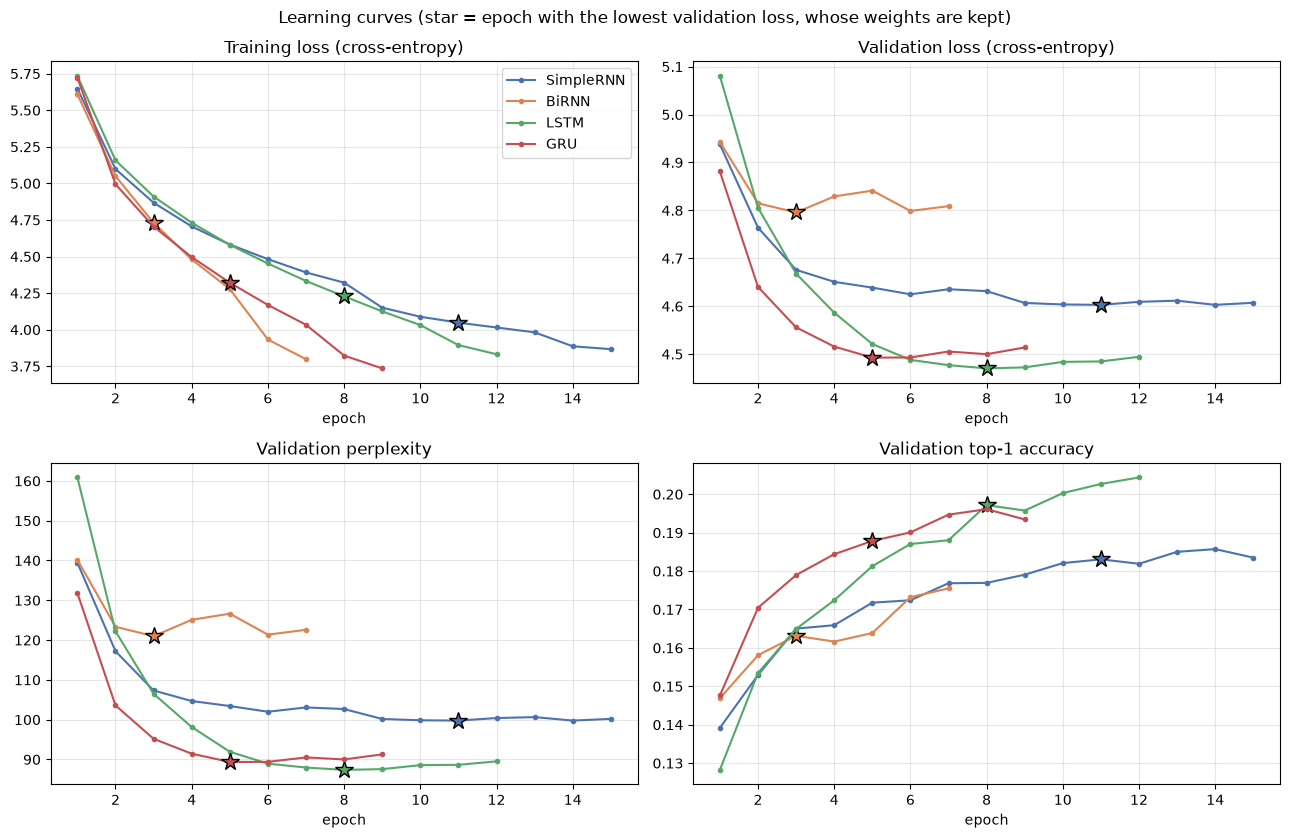

In [11]:
COLORS = {'SimpleRNN': '#4C72B0', 'BiRNN': '#DD8452', 'LSTM': '#55A868', 'GRU': '#C44E52'}
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
panels = [('train_loss', 'Training loss (cross-entropy)'), ('val_loss', 'Validation loss (cross-entropy)'),
          ('val_ppl', 'Validation perplexity'), ('val_acc', 'Validation top-1 accuracy')]
best_epochs = {i['model']: i['best_epoch'] for i in train_info}
for ax, (col, title) in zip(axes.flat, panels):
    for kind in MODEL_NAMES:
        h = history_df[history_df.model == kind]
        ax.plot(h.epoch, h[col], marker='o', ms=3, label=kind, color=COLORS[kind])
        b = h[h.epoch == best_epochs[kind]]
        ax.plot(b.epoch, b[col], marker='*', ms=13, color=COLORS[kind], markeredgecolor='black')
    ax.set_title(title); ax.set_xlabel('epoch'); ax.grid(alpha=0.3)
axes[0, 0].legend()
axes[1, 0].set_ylim(top=min(axes[1, 0].get_ylim()[1], 1000))
fig.suptitle('Learning curves (star = epoch with the lowest validation loss, whose weights are kept)')
plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/02_learning_curves.png', dpi=150)
plt.show()

## 5. Quantitative evaluation (Task ii)

Every model is evaluated on the held-out **test split** with the weights from its best validation epoch:

* **Cross-entropy loss**: mean negative log-likelihood of the true next token.
* **Perplexity** $= e^{\text{loss}}$: the effective number of equally likely choices the model is "confused" between. Lower is better.
* **Top-1 / top-5 accuracy**: how often the true next token is the most likely prediction, or among the five most likely.
* **Training time**: GPU wall-clock time spent in training epochs, until early stopping.

Two count-based baselines on the same test targets put the numbers in context: a unigram model with add-one smoothing, and an interpolated trigram language model trained on the training split, with interpolation weights tuned on the validation split. The trigram model is reused in Section 6 as an independent judge of the fluency of the generated text.

In [12]:
class InterpolatedTrigramLM:
    """Count-based trigram LM: P(w|u,v) = l3*P_ML(w|u,v) + l2*P_ML(w|v) + l1*P_add1(w).
    The weight of an unseen context is redistributed over the remaining orders. Distribution is over known words (no <pad>/<unk>)."""

    def __init__(self, ids, vocab_size, lambdas=(0.5, 0.3, 0.2)):
        excluded = {PAD, UNK}
        self.V = vocab_size - len(excluded)
        self.uni, self.bi, self.tri = Counter(), Counter(), Counter()
        self.bi_ctx, self.tri_ctx = Counter(), Counter()
        for i, w in enumerate(ids):
            if w in excluded:
                continue
            self.uni[w] += 1
            if i >= 1:
                self.bi[(ids[i - 1], w)] += 1; self.bi_ctx[ids[i - 1]] += 1
            if i >= 2:
                self.tri[(ids[i - 2], ids[i - 1], w)] += 1; self.tri_ctx[(ids[i - 2], ids[i - 1])] += 1
        self.N = sum(self.uni.values())
        self.lambdas = lambdas

    def prob(self, u, v, w):
        l3, l2, l1 = self.lambdas
        p, wsum = l1 * (self.uni[w] + 1) / (self.N + self.V), l1
        c_v = self.bi_ctx[v]
        if c_v:
            p += l2 * self.bi[(v, w)] / c_v; wsum += l2
        c_uv = self.tri_ctx[(u, v)]
        if c_uv:
            p += l3 * self.tri[(u, v, w)] / c_uv; wsum += l3
        return p / wsum

    def unigram_prob(self, w):
        return (self.uni[w] + 1) / (self.N + self.V)

    def nll(self, ids, positions):
        return -np.mean([math.log(self.prob(ids[i - 2], ids[i - 1], ids[i])) for i in positions])


def eval_positions(ids, seq_len=CFG['seq_len']):
    """The same target positions as make_sequences: index >= seq_len and target != <unk>."""
    return [i for i in range(seq_len, len(ids)) if ids[i] != UNK]

trigram = InterpolatedTrigramLM(train_ids, V)
val_pos, test_pos = eval_positions(val_ids), eval_positions(test_ids)
assert len(val_pos) == len(y_val) and len(test_pos) == len(y_test)

best = None
for l3 in np.arange(0.1, 0.81, 0.1):
    for l2 in np.arange(0.1, 0.91 - l3, 0.1):
        trigram.lambdas = (l3, l2, 1 - l3 - l2)
        val_nll = trigram.nll(val_ids, val_pos)
        if best is None or val_nll < best[0]:
            best = (val_nll, trigram.lambdas)
trigram.lambdas = best[1]
print('Trigram interpolation weights (l3, l2, l1) tuned on validation:', tuple(round(float(x), 2) for x in trigram.lambdas))

baseline_rows = []
uni_nll = -np.mean([math.log(trigram.unigram_prob(test_ids[i])) for i in test_pos])
most_common_id = max(trigram.uni, key=trigram.uni.get)
top5_ids = {w for w, _ in trigram.uni.most_common(5)}
baseline_rows.append({'model': 'Unigram baseline', 'test_loss': uni_nll, 'test_ppl': math.exp(uni_nll),
                      'test_acc': np.mean([test_ids[i] == most_common_id for i in test_pos]),
                      'test_top5': np.mean([test_ids[i] in top5_ids for i in test_pos])})
tri_nll = trigram.nll(test_ids, test_pos)
baseline_rows.append({'model': 'Interpolated trigram baseline', 'test_loss': tri_nll, 'test_ppl': math.exp(tri_nll),
                      'test_acc': np.nan, 'test_top5': np.nan})
pd.DataFrame(baseline_rows).round(4)

Trigram interpolation weights (l3, l2, l1) tuned on validation: (0.2, 0.5, 0.3)


,model,test_loss,test_ppl,test_acc,test_top5
0,Unigram baseline,5.7289,307.6252,0.0694,0.2227
1,Interpolated trigram baseline,4.7197,112.1315,NaN,NaN


In [13]:
rows = []
for info in train_info:
    kind = info['model']
    m = models[kind]
    va = run_epoch(m, X_val, y_val)
    te = run_epoch(m, X_test, y_test)
    rows.append({'model': kind,
                 'params': sum(p.numel() for p in m.parameters()),
                 'epochs_run': info['epochs_run'], 'best_epoch': info['best_epoch'],
                 'train_time_s': info['train_time_s'], 'time_per_epoch_s': info['time_per_epoch_s'],
                 'val_loss': va['loss'], 'val_ppl': va['ppl'],
                 'test_loss': te['loss'], 'test_ppl': te['ppl'], 'test_acc': te['acc'], 'test_top5': te['top5']})
comparison = pd.DataFrame(rows)
comparison_all = pd.concat([comparison, pd.DataFrame(baseline_rows)], ignore_index=True)
comparison_all.to_csv(f'{RESULTS_DIR}/model_comparison.csv', index=False)

fmt = comparison_all.copy()
for c in ['train_time_s', 'time_per_epoch_s']:
    fmt[c] = fmt[c].map(lambda x: f'{x:.1f}' if pd.notna(x) else '–')
for c in ['val_loss', 'test_loss']:
    fmt[c] = fmt[c].map(lambda x: f'{x:.4f}' if pd.notna(x) else '–')
for c in ['val_ppl', 'test_ppl']:
    fmt[c] = fmt[c].map(lambda x: f'{x:.2f}' if pd.notna(x) else '–')
for c in ['test_acc', 'test_top5']:
    fmt[c] = fmt[c].map(lambda x: f'{100 * x:.2f}%' if pd.notna(x) else '–')
for c in ['params', 'epochs_run', 'best_epoch']:
    fmt[c] = fmt[c].map(lambda x: f'{int(x):,}' if pd.notna(x) else '–')
fmt

,model,params,epochs_run,best_epoch,train_time_s,time_per_epoch_s,val_loss,val_ppl,test_loss,test_ppl,test_acc,test_top5
0,SimpleRNN,"1,738,830",15,11,31.0,2.1,4.6028,99.77,4.5286,92.63,19.14%,42.43%
1,BiRNN,"3,103,310",7,3,22.3,3.2,4.7957,120.98,4.7618,116.96,16.53%,38.92%
2,LSTM,"2,430,030",12,8,43.6,3.7,4.4703,87.38,4.4253,83.54,20.33%,43.25%
3,GRU,"2,199,630",9,5,29.4,3.1,4.4927,89.37,4.4420,84.94,19.42%,42.79%
4,Unigram baseline,–,–,–,–,–,–,–,5.7289,307.63,6.94%,22.27%
5,Interpolated trigram baseline,–,–,–,–,–,–,–,4.7197,112.13,–,–


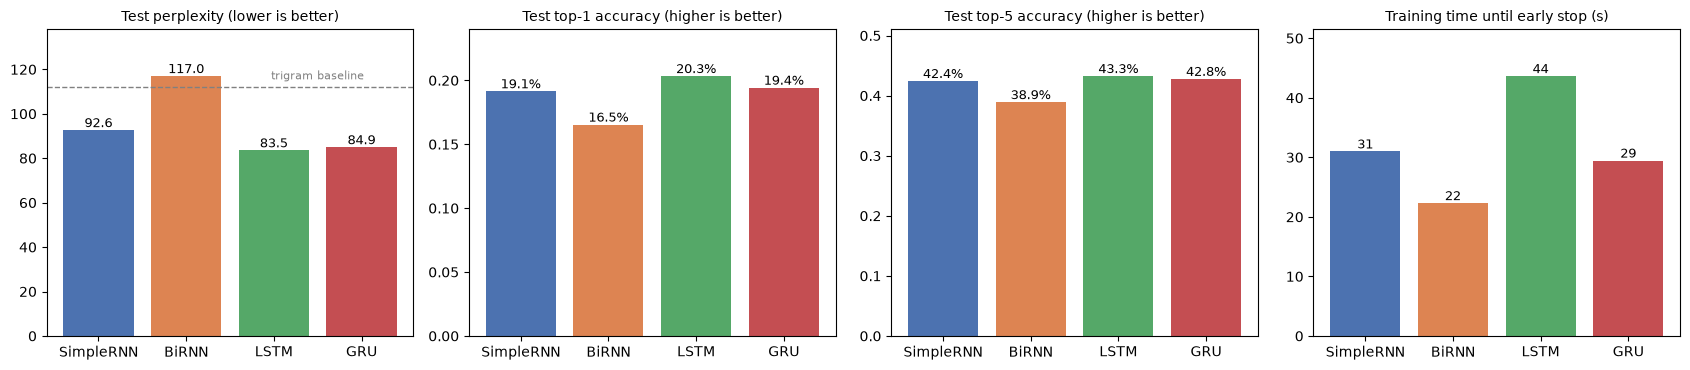

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
x = np.arange(len(MODEL_NAMES))
bars = [('test_ppl', 'Test perplexity (lower is better)', '{:.1f}'),
        ('test_acc', 'Test top-1 accuracy (higher is better)', '{:.1%}'),
        ('test_top5', 'Test top-5 accuracy (higher is better)', '{:.1%}'),
        ('train_time_s', 'Training time until early stop (s)', '{:.0f}')]
for ax, (col, title, f) in zip(axes, bars):
    vals = comparison.set_index('model').loc[MODEL_NAMES, col].values
    b = ax.bar(MODEL_NAMES, vals, color=[COLORS[k] for k in MODEL_NAMES])
    ax.bar_label(b, labels=[f.format(v) for v in vals], fontsize=9)
    ax.set_title(title, fontsize=10)
    ax.set_ylim(0, vals.max() * 1.18)
axes[0].axhline(math.exp(tri_nll), ls='--', color='grey', lw=1)
axes[0].text(2.5, math.exp(tri_nll) * 1.03, 'trigram baseline', color='grey', fontsize=8, ha='center')
plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/03_test_metrics.png', dpi=150)
plt.show()

**Is the ranking statistically reliable?** The test-set differences between some models are small, so a paired bootstrap is run on the per-token test losses: 2,000 resamples of the 11,116 test positions. The table gives the mean loss difference (negative means the first model is better), its 95 % confidence interval, and the share of resamples in which the first model has the lower loss.

In [15]:
@torch.no_grad()
def token_nll(model, X, y, bs=1024):
    model.eval()
    return torch.cat([nn.functional.cross_entropy(model(X[i:i + bs]), y[i:i + bs], reduction='none')
                      for i in range(0, len(y), bs)]).cpu().numpy()

test_nll = {k: token_nll(models[k], X_test, y_test) for k in MODEL_NAMES}
pairs = [('LSTM', 'GRU'), ('LSTM', 'SimpleRNN'), ('LSTM', 'BiRNN'), ('GRU', 'SimpleRNN'), ('GRU', 'BiRNN'), ('SimpleRNN', 'BiRNN')]
rng_np = np.random.default_rng(SEED)
boots = {p: [] for p in pairs}
for _ in range(2000):
    idx = rng_np.integers(0, len(y_test), len(y_test))
    for a, b in pairs:
        boots[(a, b)].append(test_nll[a][idx].mean() - test_nll[b][idx].mean())
sig_rows = []
for a, b in pairs:
    bs_ = np.array(boots[(a, b)])
    lo, hi = np.percentile(bs_, [2.5, 97.5])
    sig_rows.append({'comparison': f'{a} vs {b}', 'mean loss diff': (test_nll[a] - test_nll[b]).mean(),
                     '95% CI low': lo, '95% CI high': hi, 'P(first model better)': (bs_ < 0).mean()})
significance = pd.DataFrame(sig_rows)
significance.to_csv(f'{RESULTS_DIR}/bootstrap_significance.csv', index=False)
significance.round(4)

,comparison,mean loss diff,95% CI low,95% CI high,P(first model better)
0,LSTM vs GRU,-0.0167,-0.0326,-0.0013,0.9835
1,LSTM vs SimpleRNN,-0.1033,-0.1214,-0.0854,1.0000
2,LSTM vs BiRNN,-0.3366,-0.3573,-0.3167,1.0000
3,GRU vs SimpleRNN,-0.0867,-0.1048,-0.0690,1.0000
4,GRU vs BiRNN,-0.3199,-0.3390,-0.3013,1.0000
5,SimpleRNN vs BiRNN,-0.2332,-0.2528,-0.2138,1.0000


In [16]:
@torch.no_grad()
def top_k_next(model, context_ids, k=5):
    model.eval()
    ctx = context_ids[-CFG['seq_len']:]
    ctx = [PAD] * (CFG['seq_len'] - len(ctx)) + ctx
    probs = torch.softmax(model(torch.tensor([ctx], device=DEVICE))[0], dim=-1)
    p, i = probs.topk(k)
    return [(itos[j], pv) for j, pv in zip(i.tolist(), p.tolist())]

pred_rows = []
for idx in [100, 2500, 6000]:
    ctx = X_test[idx].tolist()
    true = itos[y_test[idx].item()]
    print(f"Context: ... {' '.join(itos[j] for j in ctx)}   | true next word: '{true}'")
    for kind in MODEL_NAMES:
        preds = top_k_next(models[kind], ctx)
        print(f"   {kind:<9}: " + ', '.join(f'{w} ({p:.2f})' for w, p in preds))
        pred_rows.append({'context': ' '.join(itos[j] for j in ctx), 'true_next': true, 'model': kind,
                          'top5': ', '.join(f'{w} ({p:.3f})' for w, p in preds)})
    print()
pd.DataFrame(pred_rows).to_csv(f'{RESULTS_DIR}/next_word_predictions.csv', index=False)

Context: ... say a word without <unk> his own family . well , your own good sense   | true next word: 'will'
   SimpleRNN: , (0.53), . (0.14), ? (0.12), ! (0.04), is (0.02)
   BiRNN    : , (0.38), . (0.23), ? (0.03), of (0.03), ! (0.03)
   LSTM     : , (0.30), is (0.19), . (0.12), ? (0.06), ! (0.05)
   GRU      : , (0.39), is (0.22), . (0.07), ! (0.06), ? (0.03)

Context: ... me think that perhaps he was joking . my <unk> duties , then , i   | true next word: 'asked'
   SimpleRNN: have (0.13), think (0.07), should (0.07), was (0.04), had (0.04)
   BiRNN    : have (0.16), shall (0.10), believe (0.06), am (0.04), think (0.03)
   LSTM     : am (0.09), have (0.09), think (0.08), should (0.03), had (0.03)
   GRU      : was (0.06), have (0.05), think (0.05), had (0.05), am (0.05)

Context: ... worn before . it could not have been a better fit if i had been   | true next word: 'measured'
   SimpleRNN: to (0.06), in (0.04), seen (0.04), able (0.02), of (0.02)
   BiRNN    : cut (0.12), to (0.04

### Discussion of the quantitative results

* **LSTM is the best next-word predictor** on every measure: test perplexity **83.54**, top-1 accuracy **20.33 %** and top-5 accuracy **43.25 %**. **GRU** is a close second (84.94 / 19.42 % / 42.79 %). The paired bootstrap shows the LSTM–GRU gap is small but consistent: Δloss = -0.0167 nats, 95 % CI [-0.0326, -0.0013], and LSTM is better in 98.4 % of resamples.
* **Gating matters.** Both gated models clearly beat the Simple RNN (test perplexity 92.63). The loss differences are -0.103 and -0.087 nats, and neither confidence interval contains 0. The LSTM's additive cell state and the GRU's update gate let gradients flow across the whole 15-token window. The tanh RNN suffers from vanishing gradients and relies mostly on the last few words, and its validation loss plateaus at about 4.60 from epoch 9 onwards even after the learning rate is halved.
* **The Bidirectional RNN is the weakest model.** Its test perplexity of 116.96 is worse than the Simple RNN and even slightly worse than the count-based trigram baseline (112.13). It reaches its best validation loss at epoch 3 and then overfits fastest: by epoch 7 the training loss has fallen to 3.80 while the validation loss is 4.81. There are two reasons. (1) The target word lies *after* the window, so the backward pass adds no future information. Its final state summarises the context read right-to-left and therefore ends on the *oldest* word, which is the least useful one for predicting the next word. (2) It doubles the recurrent state and the input of the output layer (512 → 3,918), giving the most parameters (3.10 M) on a corpus of only 92,634 training sequences. Bidirectionality helps when the whole sequence is visible (tagging, classification), not for left-to-right generation.
* **Convergence.** GRU converges fastest: it has the lowest validation loss in epochs 1–5 and its best epoch is 5. LSTM starts slowest (epoch-1 validation perplexity 160.9) but keeps improving until epoch 8 and finishes lowest.
* **Training time.** Median time per epoch: Simple RNN 2.1 s, GRU 3.1 s, LSTM 3.7 s, BiRNN 3.2 s. Total time until early stopping: Simple RNN 31.0 s (15 epochs), BiRNN 22.3 s (7), LSTM 43.6 s (12), GRU 29.4 s (9). The Simple RNN is the cheapest per epoch. The gated and bidirectional models cost 1.5–1.8× as much per epoch, but all are cuDNN kernels, and the shared 3,918-way softmax takes a large part of the compute. Total time mostly depends on how many epochs a model needs before early stopping. Wall-clock times on a laptop GPU vary by roughly ±15 % between runs; all other metrics are exactly reproducible.
* **Interpreting the accuracy.** Every neural model is far better than the unigram baseline (perplexity 307.6). A top-1 accuracy of about 20 % over a 3,918-word vocabulary is typical for word-level models on a corpus this size. Most hits are punctuation and function words, while open-class content words are rarely guessed exactly. The top-5 examples above show this: for *"…if i had been ___"* (true word: *measured*) the models propose plausible participles such as *cut*, *seen* and *able*.

## 6. Text generation and qualitative evaluation (Task ii)

**Autoregressive generation.** The seed is tokenised and the last 15 tokens are fed to the model. The next token is sampled from the temperature-scaled softmax $p_i \propto \exp(z_i / T)$, appended to the sequence, and the window slides forward one token. This repeats for 50 tokens. `<pad>` and `<unk>` are never sampled.

**Seed sequences.** Five seeds of 17–20 tokens. Seed 1 is the opening line of the book, so it is in the training data and tests memorisation versus generalisation. Seeds 2–5 are new sentences written in the style of the corpus.

**Automatic proxies for the qualitative criteria.** Computed on every generated continuation, 5 seeds × 10 samples = 50 continuations (2,500 tokens) per model and temperature:

| Criterion | Measure | Better |
|---|---|---|
| Coherence / fluency | **Judge perplexity**: token-level perplexity of the continuations under the independent interpolated trigram LM from Section 5, which is not one of the four models being compared. Low values mean locally fluent word sequences that resemble Doyle's text. | lower (but far below human text means the output is degenerate) |
| Diversity | **Distinct-1 / Distinct-2**: unique unigrams (bigrams) ÷ total, within a sample, punctuation excluded. **Inter-sample Distinct-2**: the same ratio pooled over the 10 samples drawn for one seed, which measures how different the samples are from each other. | higher |
| Repetition | **Rep-3**: share of word trigrams in a sample that repeat an earlier trigram, which detects loops. | lower |
| Contextual consistency | **Seed–continuation similarity**: cosine similarity between the mean word vector of the seed's content words and of the continuation's content words. The vectors are 100-d PPMI-SVD embeddings learned from training-split co-occurrences, so they are independent of the four models. | higher |

The same metrics are also computed on real 50-token passages from the held-out test text. This human reference shows what natural values look like.

These numbers support, but do not replace, reading the samples, which is done in the qualitative discussion below.

In [17]:
SEEDS = [
    'To Sherlock Holmes she is always the woman. I have seldom heard him mention her under',
    'It was a cold morning in the early spring, and Holmes was sitting in his chair by the fire',
    'The door opened and a tall man entered the room. He was dressed in a long dark coat',
    'You will excuse me, Watson, said Holmes, but I have a small problem which',
    'The lady sat down and began to tell us the strange story of her father, who had',
]
for i, s in enumerate(SEEDS, 1):
    toks = tokenize(s)
    oov = [t for t in toks if t not in stoi]
    print(f'Seed {i}: {len(toks)} tokens, OOV: {oov or "none"}')

PROPER = {'holmes', 'sherlock', 'watson', 'lestrade', 'london', 'england', 'baker', 'mr', 'mrs', 'dr', 'st'}

def detokenize(toks):
    words = [t.capitalize() if t in PROPER else t for t in toks]
    text = ' '.join(words)
    text = re.sub(r' ([.,!?;:])', r'\1', text)
    text = re.sub(r"\bi\b", 'I', text)
    text = re.sub(r'([.!?] )([a-z])', lambda m: m.group(1) + m.group(2).upper(), text)
    return text

@torch.no_grad()
def generate(model, seed_text, n_words=N_GEN_WORDS, temperature=1.0, rng=None):
    """Autoregressive sampling; returns the list of generated tokens (seed excluded)."""
    model.eval()
    ids = encode(tokenize(seed_text))
    out = []
    for _ in range(n_words):
        ctx = ids[-CFG['seq_len']:]
        ctx = [PAD] * (CFG['seq_len'] - len(ctx)) + ctx
        logits = model(torch.tensor([ctx], device=DEVICE))[0].float()
        logits[[PAD, UNK]] = -float('inf')
        probs = torch.softmax(logits / temperature, dim=-1).cpu()
        nxt = torch.multinomial(probs, 1, generator=rng).item()
        ids.append(nxt)
        out.append(itos[nxt])
    return out

Seed 1: 17 tokens, OOV: none
Seed 2: 20 tokens, OOV: none
Seed 3: 19 tokens, OOV: none
Seed 4: 17 tokens, OOV: none
Seed 5: 18 tokens, OOV: none


In [18]:
STOPWORDS = set("""a about above after again against all am an and any are as at be because been before being below between both
but by can could did do does doing down during each few for from further had has have having he her here hers herself him
himself his how i if in into is it its itself just me more most my myself no nor not now of off on once only or other our
ours ourselves out over own same shall she should so some such than that the their theirs them themselves then there these
they this those through to too under until up upon very was we were what when where which while who whom why will with would
you your yours yourself yourselves i'm i've i'll it's that's there's don't one may might must said say says see seen come came
little well yes no sir""".split())

def build_word_vectors(ids, window=4, n_ctx=2000, dim=100):
    """PPMI-SVD word vectors from training-split co-occurrences (context columns = frequent content words)."""
    content = [i for i in range(2, V) if itos[i] not in STOPWORDS and itos[i] not in PUNCT][:n_ctx]
    ctx_map = -np.ones(V, dtype=np.int64)
    ctx_map[content] = np.arange(len(content))
    M = np.zeros((V, len(content)))
    arr = np.array(ids)
    for off in range(1, window + 1):
        for a, b in ((arr[:-off], arr[off:]), (arr[off:], arr[:-off])):
            mask = ctx_map[b] >= 0
            np.add.at(M, (a[mask], ctx_map[b[mask]]), 1.0)
    total = M.sum()
    p_w = M.sum(1, keepdims=True) / total
    p_c = M.sum(0) ** 0.75
    p_c /= p_c.sum()
    with np.errstate(divide='ignore', invalid='ignore'):
        pmi = np.log((M / total) / (p_w * p_c[None, :]))
    ppmi = np.nan_to_num(np.maximum(pmi, 0), nan=0.0, posinf=0.0, neginf=0.0)
    U, S, _ = np.linalg.svd(ppmi, full_matrices=False)
    vecs = U[:, :dim] * np.sqrt(S[:dim])
    return vecs / (np.linalg.norm(vecs, axis=1, keepdims=True) + 1e-8)

word_vecs = build_word_vectors(train_ids)

def neighbours(word, k=6):
    sims = word_vecs @ word_vecs[stoi[word]]
    return [itos[i] for i in np.argsort(-sims)
            if i > 1 and itos[i] != word and itos[i] not in STOPWORDS and itos[i] not in PUNCT][:k]

print('Sanity check of the PPMI-SVD vectors (nearest content-word neighbours):')
for w in ['holmes', 'door', 'money', 'father', 'morning', 'police']:
    print(f'  {w:<8} -> {", ".join(neighbours(w))}')

Sanity check of the PPMI-SVD vectors (nearest content-word neighbours):
  holmes   -> sherlock, mr, back, occupation, cried, tut
  door     -> open, lock, flew, behind, flung, landau
  money    -> australia, sum, enable, borrowed, nonsense, degrees
  father   -> 84, amused, affectionate, begged, quarrel, cry
  morning  -> cloudless, april, yesterday, o'clock, morrow, crumpled
  police   -> hopeless, constable, official, informed, ended, anywhere


In [19]:
def ngrams(seq, n):
    return [tuple(seq[i:i + n]) for i in range(len(seq) - n + 1)]

def content_vector(toks):
    ids = [stoi[t] for t in toks if t in stoi and t not in STOPWORDS and t not in PUNCT]
    return word_vecs[ids].mean(0) if ids else None

def text_metrics(seed_text, cont):
    words = [t for t in cont if t not in PUNCT]
    bi, tri = ngrams(words, 2), ngrams(words, 3)
    seed_ids, cont_ids = encode(tokenize(seed_text)), encode(cont)
    full = seed_ids + cont_ids
    positions = [i for i in range(len(seed_ids), len(full)) if full[i] != UNK]   # (generated text never contains <unk>)
    judge_nll = -np.mean([math.log(trigram.prob(full[i - 2], full[i - 1], full[i])) for i in positions])
    sv, cv = content_vector(tokenize(seed_text)), content_vector(cont)
    sim = float(sv @ cv / (np.linalg.norm(sv) * np.linalg.norm(cv) + 1e-8)) if sv is not None and cv is not None else np.nan
    return {'distinct1': len(set(words)) / max(len(words), 1),
            'distinct2': len(set(bi)) / max(len(bi), 1),
            'rep3': 1 - len(set(tri)) / max(len(tri), 1),
            'judge_nll': judge_nll,
            'judge_ppl': math.exp(judge_nll),
            'context_sim': sim}

gen_rows = []
t0 = time.perf_counter()
for m_idx, kind in enumerate(MODEL_NAMES):
    for T in TEMPERATURES:
        for s_idx, seed_text in enumerate(SEEDS, 1):
            for k in range(N_SAMPLES_PER_SEED):
                # independent random stream per (model, seed, sample); reused across temperatures,
                # so for a given model the differences between temperatures come from T alone
                rng = torch.Generator().manual_seed(1000 * s_idx + 100 * m_idx + k)
                cont = generate(models[kind], seed_text, temperature=T, rng=rng)
                gen_rows.append({'model': kind, 'temperature': T, 'seed_id': s_idx, 'sample': k + 1,
                                 'seed': seed_text, 'generated': detokenize(cont), 'tokens': ' '.join(cont),
                                 **text_metrics(seed_text, cont)})
gen_df = pd.DataFrame(gen_rows)
print(f'Generated {len(gen_df)} samples x {N_GEN_WORDS} tokens in {time.perf_counter() - t0:.1f}s')

# inter-sample diversity: distinct-2 pooled over the samples drawn for the same (model, T, seed)
def pooled_distinct2(token_strings):
    bis = [b for s in token_strings for b in ngrams([t for t in s.split() if t not in PUNCT], 2)]
    return len(set(bis)) / max(len(bis), 1)

inter = (gen_df.groupby(['model', 'temperature', 'seed_id'])['tokens'].apply(lambda s: pooled_distinct2(list(s)))
         .rename('inter_distinct2').reset_index())
gen_df.to_csv(f'{RESULTS_DIR}/generation_samples_and_metrics.csv', index=False)

Generated 800 samples x 50 tokens in 45.9s


In [20]:
METRICS = ['judge_ppl', 'distinct1', 'distinct2', 'inter_distinct2', 'rep3', 'context_sim']
grouped = gen_df.groupby(['model', 'temperature'])
summary = grouped[['distinct1', 'distinct2', 'rep3', 'context_sim']].mean()
summary.insert(0, 'judge_ppl', np.exp(grouped['judge_nll'].mean()))   # token-level perplexity over all generated tokens
summary = summary.join(inter.groupby(['model', 'temperature'])['inter_distinct2'].mean()).reset_index()
summary['model'] = pd.Categorical(summary['model'], MODEL_NAMES, ordered=True)
summary = summary.sort_values(['model', 'temperature'])[['model', 'temperature'] + METRICS].reset_index(drop=True)
summary['model'] = summary['model'].astype(str)
summary.to_csv(f'{RESULTS_DIR}/temperature_summary.csv', index=False)

# Reference values: the same metrics on real 50-token passages from the held-out test text
ref_rows = []
for start in range(0, len(test_tok) - 70, 700):
    seed_toks, cont = test_tok[start:start + 17], test_tok[start + 17:start + 17 + N_GEN_WORDS]
    ref_rows.append(text_metrics(' '.join(seed_toks), cont))
ref_df = pd.DataFrame(ref_rows)
reference = ref_df.drop(columns=['judge_nll']).mean()
reference['judge_ppl'] = math.exp(ref_df['judge_nll'].mean())
reference.to_csv(f'{RESULTS_DIR}/human_text_reference_metrics.csv', header=['value'])
print(f'Reference values for human-written test text ({len(ref_rows)} passages of {N_GEN_WORDS} tokens):')
print(reference.round(3).to_string(), '\n')
summary.round(3)

Reference values for human-written test text (18 passages of 50 tokens):
distinct1        0.832
distinct2        0.985
rep3             0.003
judge_ppl      110.553
context_sim      0.291 



,model,temperature,judge_ppl,distinct1,distinct2,inter_distinct2,rep3,context_sim
0,SimpleRNN,0.2,19.169,0.544,0.766,0.341,0.138,0.296
1,SimpleRNN,0.5,27.788,0.694,0.929,0.701,0.017,0.307
2,SimpleRNN,1.0,137.410,0.846,0.992,0.944,0.001,0.340
3,SimpleRNN,1.5,1035.154,0.926,0.999,0.995,0.000,0.332
4,BiRNN,0.2,22.709,0.549,0.796,0.397,0.082,0.279
5,BiRNN,0.5,31.726,0.648,0.909,0.646,0.013,0.306
6,BiRNN,1.0,145.806,0.826,0.991,0.928,0.000,0.311
7,BiRNN,1.5,1162.857,0.926,1.000,0.995,0.000,0.317
8,LSTM,0.2,17.808,0.501,0.720,0.273,0.147,0.275
9,LSTM,0.5,31.380,0.678,0.929,0.681,0.010,0.342


In [21]:
def write_samples_markdown(path):
    lines = ['# Generated text samples', '',
             f'Each continuation is {N_GEN_WORDS} tokens long. Sample 1 of {N_SAMPLES_PER_SEED} is shown for every '
             '(seed, model, temperature); all samples are in `generation_samples_and_metrics.csv`.', '']
    for s_idx, seed_text in enumerate(SEEDS, 1):
        lines += [f'## Seed {s_idx}', '', f'> **Seed:** {seed_text}', '']
        for T in TEMPERATURES:
            lines += [f'### Temperature {T}', '']
            for kind in MODEL_NAMES:
                r = gen_df[(gen_df.model == kind) & (gen_df.temperature == T) & (gen_df.seed_id == s_idx) & (gen_df['sample'] == 1)].iloc[0]
                lines += [f'- **{kind}**: …{r.generated}']
            lines += ['']
    with open(path, 'w', encoding='utf-8') as f:
        f.write('\n'.join(lines))

write_samples_markdown(f'{RESULTS_DIR}/generated_samples.md')

def show(seed_id, temps=TEMPERATURES, sample=1):
    print(f'SEED {seed_id}: "{SEEDS[seed_id - 1]}"\n')
    for T in temps:
        print(f'--- temperature {T} ---')
        for kind in MODEL_NAMES:
            r = gen_df[(gen_df.model == kind) & (gen_df.temperature == T) & (gen_df.seed_id == seed_id) & (gen_df['sample'] == sample)].iloc[0]
            print(f'[{kind}] {r.generated}\n')

show(2)

SEED 2: "It was a cold morning in the early spring, and Holmes was sitting in his chair by the fire"

--- temperature 0.2 ---
[SimpleRNN] , and the colonel was shining brightly, and the windows of the red headed league, and the other of the bride, and the whole place of the deceased. I was glad to me, and I have been able to think that I have been able

[BiRNN] of the house. I have a quiet, and he has been to be a little more of the palm of the house, and the ominous of the window. I have been cut to the station. Then, I have been cut to the station.

[LSTM] . I had been the door of the house, and I have no doubt that I had been able to be the matter. I have no doubt that I have been able to be a little of the matter. I have no doubt to see you.

[GRU] of the mantelpiece. I had seen the door, and I was glad to be able to the police. I was aware to my friend, and I had not seen the door of the city. I was glad to my friend, and I had seen

--- temperature 0.5 ---
[SimpleRNN] . I think t

In [22]:
show(1, temps=[0.2, 0.5])

SEED 1: "To Sherlock Holmes she is always the woman. I have seldom heard him mention her under"

--- temperature 0.2 ---
[SimpleRNN] the door. I was glad to the police. I have been shamefully to be a little more than the matter. I have heard of the matter, and I have no doubt that I should be happy to be found. It was a few minutes of

[BiRNN] ? I have been able to the station of the window. I have no doubt that there is a little man, and I have got to go. I have a little man. I shall be no doubt that I have got to the floor. I

[LSTM] the matter. I am not glad to see that you are in the matter. I am afraid that I am not a little one of the matter. I am afraid that I had been to do. I have no doubt that I have been to my

[GRU] . It is a little thing, and I shall be happy to see you. I have been able to my friend. I have been some little enough to be able to go to the police. I have been seen to the police. I have not

--- temperature 0.5 ---
[SimpleRNN] upon the ground. It is a very s

In [23]:
show(3, temps=[0.5, 1.0])

SEED 3: "The door opened and a tall man entered the room. He was dressed in a long dark coat"

--- temperature 0.5 ---
[SimpleRNN] , which was a paragraph, hanging, but the whole mccarthys had been drawn in his chair, and I knew that the coroner was there, the body was shining, for he was a man who leads his father to the floor, and my suspicions is

[BiRNN] of the lamp. It was a great result, and I do not know that to do it, and I have no use with a little thing. I have a very bad of the window. I have been seen to be a very note. But

[LSTM] , and by the door of the grey keeper with the daughter of the house. It is a very affair, and that part of the morning, I am afraid to you that I had no doubt to see anything of the door. You have been the

[GRU] , and his face was a long man in the front of the mantelpiece. I have been seen to be able to think, but I have been able to be seen in my own cases. I shall not have been able to be at the case.

--- temperature 1.0 ---
[SimpleRNN] , ke

In [24]:
for s in (4, 5):
    show(s, temps=[0.5])

SEED 4: "You will excuse me, Watson, said Holmes, but I have a small problem which"

--- temperature 0.5 ---
[SimpleRNN] he had been in the same room. I have been senseless to me, and I have been to be a policeman and to the police, but you are to go. I have seen it, and I have been, with the same intention of the

[BiRNN] is a little, and I should be able to the floor. I have a wild that he would be a little more of the ground. I should be the address. I have not the pleasure of the time. But I think that I had no

[LSTM] I found the dead hand. I must call you, and I should be hard to follow. I am afraid to call at the morning. There is no one, and, as I had not been seen myself, and I have seen him to my

[GRU] I had done. My dear fellow, said he, the salesman is a very serious man, and I shall have been to you. I have been able to my friend and used in the morning. I have been a very busy and looking in the

SEED 5: "The lady sat down and began to tell us the strange story of her fa

### Qualitative comparison of the generated text

All four models have learned the surface style of the corpus: first-person narration (*"I had been…"*, *"I have no doubt that…"*), dialogue tags (*"said he"*, *"said Holmes"*, *"I remarked"*), Victorian phrasing (*"my dear fellow"*, *"I am afraid that"*, *"the matter"*) and sensible punctuation. Within a span of 5–10 words the output is mostly grammatical. None of the models is coherent across a whole paragraph, which is expected with a 15-token context and about 96k training tokens. Observations at the recommended temperature **T = 0.5**:

| Model | Coherence and grammar | Diversity / repetition | Contextual consistency |
|---|---|---|---|
| **Simple RNN** | Locally fluent, but often breaks agreement and jumps topic mid-sentence: *"the moment was an old feet, and the fierce of balmoral"*. | Highest lexical variety (Distinct-1 0.694, inter-sample Distinct-2 0.701); Rep-3 0.017. | Drifts quickly away from the seed, e.g. seed 5: *"…who had been drawn out of the window … a magnifying face … the red headed league"*. |
| **BiRNN** | Least grammatical. Adjectives often lack their nouns: *"a very bad of the window"*, *"I have a wild that he would be"*, *"a very serious of the table"*. This matches its highest test perplexity. | Lowest within-sample Distinct-2 after GRU (0.909); at T = 0.2 it falls into loops (*"I have been cut to the station. Then, I have been cut to the station."*). | Low seed–continuation similarity at T = 0.5 (0.306, level with the Simple RNN). |
| **LSTM** | The most sentence-like output, with clear clause structure and dialogue turns: *"I found the dead hand. I must call you, and I should be hard to follow."*; *"To me, said he. That is it? I am sure…"*. | Lowest repetition (Rep-3 0.010) and joint-highest within-sample diversity (Distinct-2 0.929). | Holds on to the seed's referent, e.g. seed 5: *"…the lady … The name of the lady is so good"*; similarity 0.342. |
| **GRU** | Produces some of the most Holmes-like lines (*"My dear fellow, said he, the salesman is a very serious man"*), but falls back on high-frequency stock phrases (*"I have been able to be seen"*, *"the police of the city"*). | Most repetitive at low temperature (Rep-3 0.158 at T = 0.2 and 0.028 at T = 0.5) and lowest Distinct-1/2. | Highest seed–continuation similarity at T = 0.5 (0.360). |

**Contextual consistency.** Every model stays on the seed's topic for about one clause and then drifts towards generic high-frequency phrases (*the matter*, *the police*, *the door*, *the window*). For seed 3 (*a tall man entered the room … dressed in a long dark coat*), the GRU (*"and his face was a long man in the front of the mantelpiece"*) and the LSTM (*"and by the door of the grey keeper with the daughter of the house"*) stay inside the room-and-visitor scene. The seed–continuation similarity proxy lies between 0.27 and 0.36 for every model and temperature, against 0.29 for real text. It therefore separates the models only weakly, and the judgement above relies mainly on reading the samples.

**No memorisation.** Seed 1 is the opening of the book and appears in the training data. None of the 160 seed-1 continuations reproduces the original text (*"…under any other name. In his eyes she eclipses…"*), even at T = 0.2. With early stopping, the models learned the style rather than copying passages.

**A caveat on judge perplexity.** At T = 0.5 the Simple RNN gets the lowest judge perplexity (27.8, against LSTM 31.4). The trigram judge only sees the previous two words, so it rewards a model whose predictions depend mainly on the last two words, which describes the Simple RNN. Judge perplexity measures *local* fluency only. Test perplexity on real held-out text (Section 5) measures much better how well a model captures the language.

## 7. Sampling-temperature analysis (Task iii)

Temperature $T$ rescales the logits before the softmax: $p_i = \exp(z_i/T) / \sum_j \exp(z_j/T)$.

* $T < 1$ sharpens the distribution towards the most likely words: safer and more fluent, but repetitive.
* $T = 1$ samples from the model's own learned distribution.
* $T > 1$ flattens it, giving rare words more probability: more diverse, but less coherent.

Every model and temperature uses the same five seeds. Within a model, the same random stream is reused at every temperature, so differences between temperatures come from $T$ alone. This is also why a model's T = 1.0 and T = 1.5 samples sometimes start with the same words.

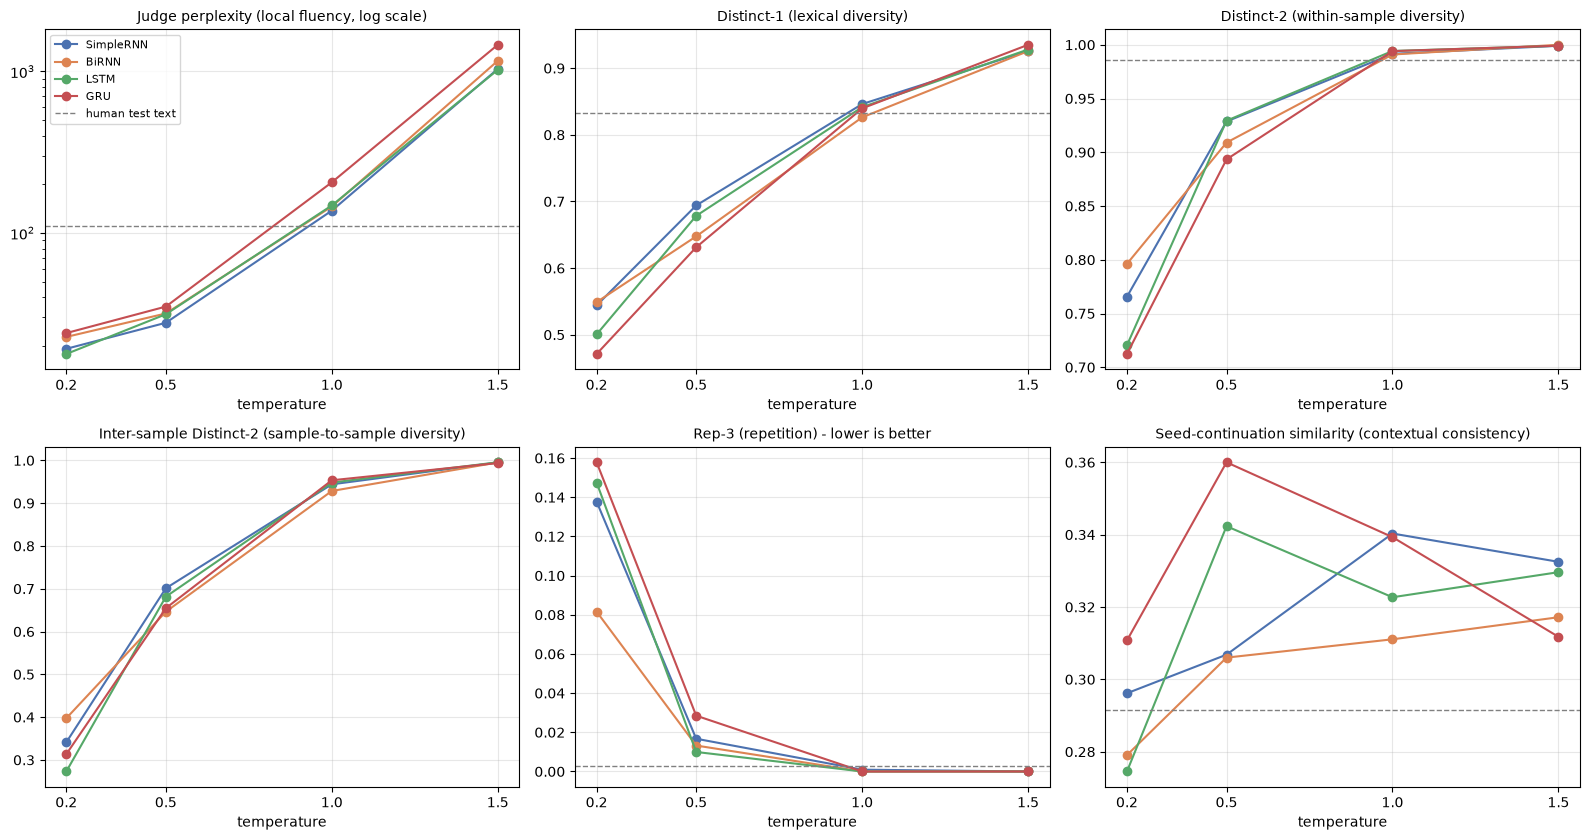

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
titles = {'judge_ppl': 'Judge perplexity (local fluency, log scale)',
          'distinct1': 'Distinct-1 (lexical diversity)',
          'distinct2': 'Distinct-2 (within-sample diversity)',
          'inter_distinct2': 'Inter-sample Distinct-2 (sample-to-sample diversity)',
          'rep3': 'Rep-3 (repetition) - lower is better',
          'context_sim': 'Seed-continuation similarity (contextual consistency)'}
for ax, metric in zip(axes.flat, METRICS):
    for kind in MODEL_NAMES:
        s = summary[summary.model == kind]
        ax.plot(s.temperature, s[metric], marker='o', label=kind, color=COLORS[kind])
    if metric in reference.index:
        ax.axhline(reference[metric], ls='--', color='grey', lw=1, label='human test text')
    ax.set_title(titles[metric], fontsize=10)
    ax.set_xlabel('temperature'); ax.set_xticks(TEMPERATURES); ax.grid(alpha=0.3)
axes[0, 0].set_yscale('log')
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/04_temperature_effects.png', dpi=150)
plt.show()

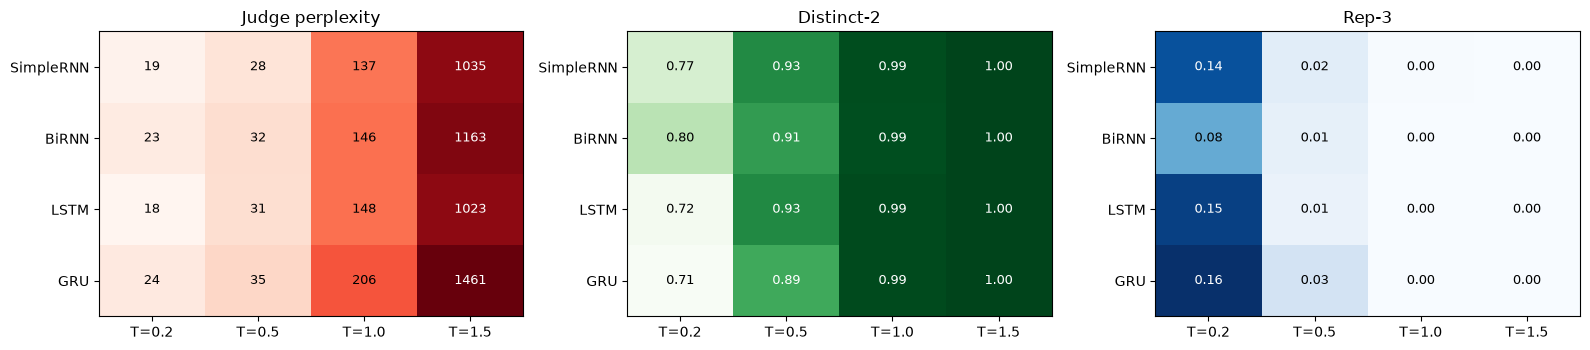

In [26]:
pivot = summary.pivot(index='model', columns='temperature', values=['judge_ppl', 'distinct2', 'rep3'])
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
for ax, (metric, cmap, title) in zip(axes, [('judge_ppl', 'Reds', 'Judge perplexity'), ('distinct2', 'Greens', 'Distinct-2'), ('rep3', 'Blues', 'Rep-3')]):
    data = pivot[metric].loc[MODEL_NAMES]
    shown = np.log10(data.values) if metric == 'judge_ppl' else data.values
    ax.imshow(shown, cmap=cmap, aspect='auto')
    ax.set_xticks(range(len(TEMPERATURES)), [f'T={t}' for t in TEMPERATURES])
    ax.set_yticks(range(len(MODEL_NAMES)), MODEL_NAMES)
    norm = (shown - shown.min()) / (shown.max() - shown.min())
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            v = data.values[i, j]
            ax.text(j, i, f'{v:.0f}' if metric == 'judge_ppl' else f'{v:.2f}', ha='center', va='center', fontsize=9,
                    color='white' if norm[i, j] > 0.6 else 'black')
    ax.set_title(title)
plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/05_temperature_heatmaps.png', dpi=150)
plt.show()

### Influence of temperature

| T | Coherence (judge PPL; human text = 110.6) | Diversity (Distinct-2; human = 0.985) | Sample-to-sample diversity | Repetition (Rep-3; human = 0.003) | What the text looks like |
|---|---|---|---|---|---|
| **0.2** | 17.8–24.0: far *below* human text, so over-predictable | 0.712–0.796 | 0.273–0.397: the 10 samples largely repeat each other | **0.082–0.158**: loops | Grammatical but degenerate stock phrases repeated: *"I had been the door of the house, and I have no doubt that I had been able to be the matter. I have no doubt that I…"* (LSTM) |
| **0.5** | 27.8–35.0: fluent | 0.893–0.929 | 0.646–0.701 | 0.010–0.028 | **Best balance**: varied, grammatical clauses that keep the seed topic for a clause or two |
| **1.0** | 137.4–205.8: above human text | 0.991–0.994: human level | 0.928–0.953 | 0.000–0.001 | Rare words in the wrong places break the syntax: *"Four our door, as to a door. Then godfrey than had begun up down it over the other door. It was an hour's as…"* (Simple RNN) |
| **1.5** | 1023–1461: about 10× human text | 0.999–1.000 | 0.994–0.995 | 0.000–0.000 | Word salad, diverse but meaningless: *"Cigar to be the obstacle past old evidence, no, burned your purposes, she must might now companions yet and…"* (LSTM) |

* **Coherence decreases monotonically with temperature.** Judge perplexity rises from about 20 at T = 0.2 to over 1,000 at T = 1.5. Low temperatures concentrate probability on the few most frequent continuations. High temperatures give the long tail of rare words enough mass to be sampled often. The models' own perplexity on real text is 84–117, so they are uncertain about the next word, and at T ≥ 1 that uncertainty turns into frequent low-probability choices that derail the sentence.
* **Diversity increases and repetition decreases monotonically.** Distinct-2 goes from 0.712–0.796 at T = 0.2 to ≈ 1.0 at T = 1.5, and Rep-3 from 0.082–0.158 to 0. At T = 0.2 the samples for a seed largely repeat each other (inter-sample Distinct-2 0.273–0.397) and often get stuck in loops. By T = 1.0 diversity matches human text, but coherence is gone.
* **Contextual consistency** is best at low-to-moderate temperatures when the text is read. The seed topic survives for a clause at T = 0.2–0.5 and is lost almost immediately at T = 1.5. The embedding-based proxy stays within a narrow band and shows no clear monotonic trend.
* **Best temperature: T ≈ 0.5 among those tested.** It removes most of the repetition seen at T = 0.2 (Rep-3 drops from 0.082–0.158 to 0.010–0.028) while the text stays fluent (judge PPL 27.8–35.0), well before the breakdown at T ≥ 1.0. Lower temperatures loop; higher ones lose grammar. The judge perplexity at T = 0.5 is still below that of human text (110.6), so the true optimum probably lies between 0.5 and 1.0 (e.g. 0.6–0.7).
* **Model × temperature.** At T = 0.5 the LSTM has the lowest repetition (0.010) and the joint-highest Distinct-2 (0.929). The GRU is the most repetitive (0.028), and the BiRNN has the lowest sample-to-sample diversity (0.646). At T = 0.2 the LSTM produces the most fluent text by the judge (17.8). At T ≥ 1.0 all models degrade sharply, the GRU most by the judge (205.8 at T = 1.0 against 137.4–147.9 for the others). At that point the temperature matters more than the architecture.

## 8. Conclusion: the most effective autoregressive model

**The LSTM is the most effective autoregressive text generator for this dataset**, for three reasons:

1. **It is the best language model.** It has the lowest test perplexity (83.54): 1.7 % lower than GRU, 9.8 % lower than Simple RNN and 28.6 % lower than BiRNN. It also has the highest top-1 (20.33 %) and top-5 (43.25 %) accuracy. Its advantage over every other model holds in the paired bootstrap (≥ 98.4 % of resamples).
2. **It generates the best text at the best temperature (T = 0.5).** It has the lowest repetition (Rep-3 0.010) and the joint-highest diversity (Distinct-2 0.929). Its sentences have the clearest clause and dialogue structure, and in the samples it holds on to the seed's referent (e.g. *the lady* in seed 5).
3. **Its gated cell state** carries information across the full 15-token context, which is exactly what next-word prediction needs.

Its only cost is training time (43.6 s, the longest, because it improves for more epochs), which is negligible at this scale.

**Ranking:** LSTM > GRU > Simple RNN > Bidirectional RNN.

* **GRU** is a close runner-up and the better choice under a tight compute budget. It is within 1.7 % of the LSTM's perplexity, uses fewer parameters (2.20 M vs 2.43 M) and converges in fewer epochs (best epoch 5 vs 8). Its generations are more repetitive, however.
* **Simple RNN** is cheap and locally fluent but uses long context poorly.
* **Bidirectional RNN** is the least suitable. Reading the context backwards adds no information about a word that lies after the window. It doubles the model's size, overfits after 3 epochs and ends up no better than a trigram model.

**Recommended configuration:** LSTM with sampling temperature T ≈ 0.5.

**Limitations and possible improvements.** The corpus is small (about 96k training tokens), so all models lose global coherence beyond a sentence. Likely improvements: a larger Doyle corpus (all four novels and five collections), a longer context, many-to-many training (a loss at every position), weight tying between the embedding and output layers, top-k or nucleus sampling, and a Transformer decoder for comparison.

In [27]:
final = comparison.set_index('model')[['test_ppl', 'test_acc', 'test_top5', 'train_time_s', 'params']].copy()
for T in TEMPERATURES:
    final[f'judge_ppl@T={T}'] = summary[summary.temperature == T].set_index('model')['judge_ppl']
final['rep3@T=0.5'] = summary[summary.temperature == 0.5].set_index('model')['rep3']
final['distinct2@T=1.0'] = summary[summary.temperature == 1.0].set_index('model')['distinct2']
final.to_csv(f'{RESULTS_DIR}/final_summary.csv')
final.round(3)

,test_ppl,test_acc,test_top5,train_time_s,params,judge_ppl@T=0.2,judge_ppl@T=0.5,judge_ppl@T=1.0,judge_ppl@T=1.5,rep3@T=0.5,distinct2@T=1.0
model,,,,,,,,,,,
SimpleRNN,92.630,0.191,0.424,30.979,1738830,19.169,27.788,137.410,1035.154,0.017,0.992
BiRNN,116.961,0.165,0.389,22.304,3103310,22.709,31.726,145.806,1162.857,0.013,0.991
LSTM,83.536,0.203,0.433,43.637,2430030,17.808,31.380,147.936,1022.704,0.010,0.994
GRU,84.941,0.194,0.428,29.448,2199630,23.986,35.002,205.766,1461.086,0.028,0.994
